# 02 · NumPy x PyTorch

Pré-requisito: `python -m src.torch_nn.train --config configs/torch_mlp.yaml --evaluate-test` e `python -m scripts.compare_numpy_torch`.

In [1]:
import sys
sys.path.append("..")
import os
os.chdir("..")  # roda a partir da raiz do projeto, como os scripts

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## 1. Tabela comparativa

In [2]:
from IPython.display import Markdown
Markdown(open("results/comparacao_numpy_torch.md", encoding="utf-8").read())

| Critério | NumPy | PyTorch |
| --- | --- | --- |
| Melhor acurácia de validação (%) | 89.68 | 89.73 |
| Épocas até o early stopping | 28 | 21 |
| Segundos por época | 2.3 | 1.7 |
| Linhas de código | 374 | 212 |
| Cálculo do gradiente | manual (backward à mão) | automático (autograd) |


## 2. Curvas sobrepostas

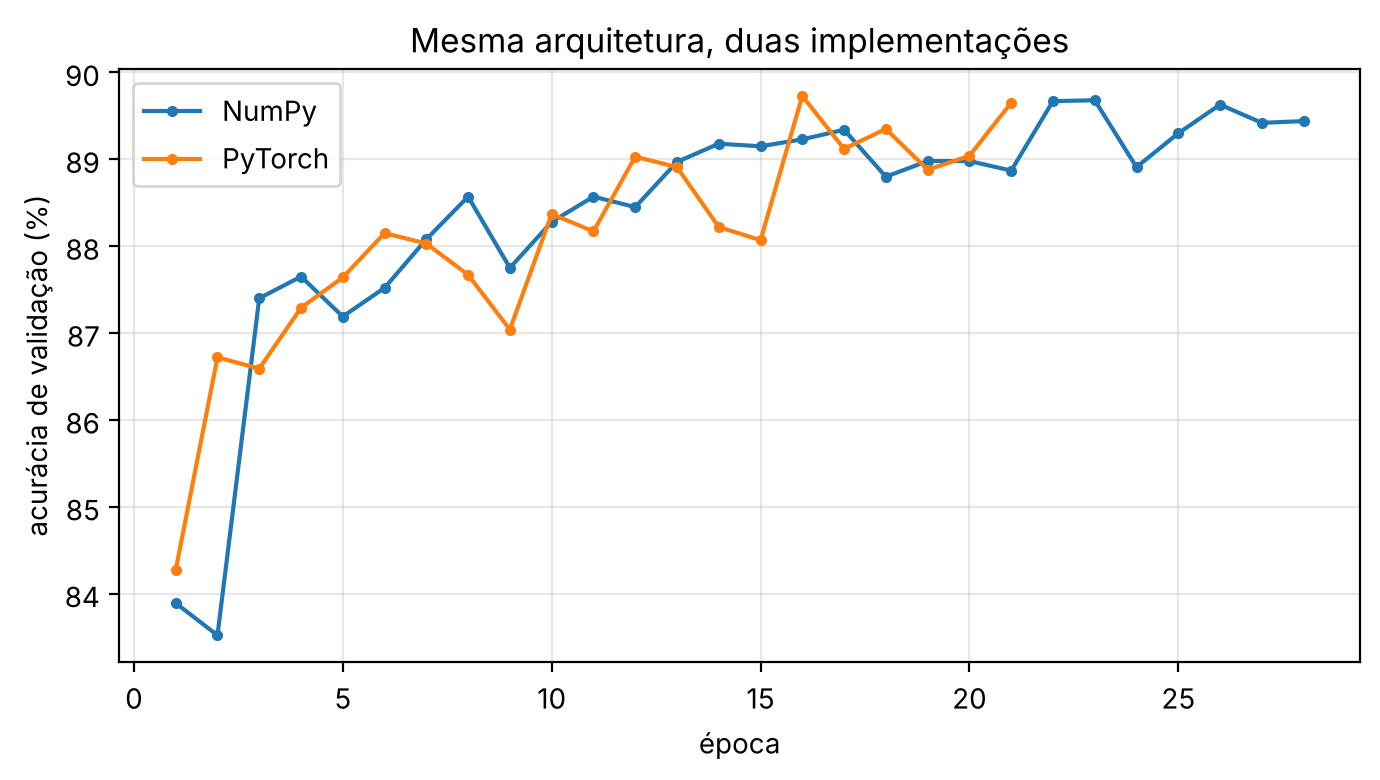

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, path in [("NumPy", "numpy_mlp"), ("PyTorch", "torch_mlp")]:
    d = pd.read_csv(f"results/{path}/metrics.csv")
    ax.plot(d.epoch, 100 * d.val_acc, marker=".", label=name)
ax.set(xlabel="época", ylabel="acurácia de validação (%)", title="Mesma arquitetura, duas implementações")
ax.legend(); ax.grid(alpha=.3); plt.tight_layout()

As curvas não são idênticas porque a ordem dos batches e a inicialização usam geradores aleatórios diferentes. A prova de que as duas implementações calculam a mesma coisa está no teste `tests/test_equivalence.py`: com os mesmos pesos, perda e gradientes coincidem até 1e-8.

## 3. A equivalência, ao vivo

In [4]:
import torch
from src.numpy_nn import SoftmaxCrossEntropy
from src.numpy_nn.model import build_mlp
from src.torch_nn.models import MLP

rng = np.random.default_rng(0)
np_model = build_mlp(784, [32, 16], 10, rng=rng)
th_model = MLP([32, 16]).double()
dense = [l for l in np_model.layers if hasattr(l, "W")]
linear = [m for m in th_model.modules() if isinstance(m, torch.nn.Linear)]
for d, lin in zip(dense, linear):
    lin.weight.data = torch.from_numpy(d.W.T.copy()); lin.bias.data = torch.from_numpy(d.b.copy())

x, y = rng.normal(size=(8, 784)), rng.integers(0, 10, 8)
ce = SoftmaxCrossEntropy()
l_np = ce.forward(np_model.forward(x), y); np_model.backward(ce.backward())
l_th = torch.nn.functional.cross_entropy(th_model(torch.from_numpy(x)), torch.from_numpy(y)); l_th.backward()
print(f"perda NumPy {l_np:.12f} | PyTorch {l_th.item():.12f}")
print("maior diferença em dW:", max(np.abs(d.dW - l.weight.grad.numpy().T).max() for d, l in zip(dense, linear)))

perda NumPy 2.521617413303 | PyTorch 2.521617413322
maior diferença em dW: 6.106226635438361e-16


## 4. O que o autograd faz por você

No NumPy, cada camada precisou de um `backward` escrito à mão. No PyTorch, cada operação registra num grafo como calcular sua derivada, e `loss.backward()` percorre esse grafo de trás para frente aplicando a regra da cadeia: o mesmo algoritmo de `Sequential.backward`, generalizado para qualquer composição de operações.